# Ignition density grids by cause

FSim-style ignition density grids (IDG) from FPA-FOD, split by **human** and **natural (lightning)** cause, with a
combined map, a human-share map and a difference map — to show where each kind of fire starts on the landscape —
plus the large fires (≥ 1,000 ac) as points by cause.

- **Method**: each cause's ignition points (**all sizes, A–G**) are kernel-smoothed onto one grid. Absolute
  units, so causes add (`all`) and subtract (`difference`). `ignition_density_grid` returns the FSim-style annual
  rate (fires / yr / 100 km²); the maps and GeoTIFFs here use **ignitions per km² over the mapped years**
  (`MAP_UNITS`, via `convert_density_units`) — the same pattern, easier to read. §5 puts the time back in as
  ignitions per year by county, plus the long federal-only record.
- **Years (`YEARS`).** Before 2010 the FOD here is almost all federal-agency reports; state & local reporting,
  which adds the private-land and plains fires, is complete from 2013 (2011 has no causes, 2012 is nearly empty;
  §2, §5). The maps start after the switch so every land owner is covered the same way.
- **Adaptive kernel** (Abramson's square-root law): each fire's Gaussian σ shrinks where fires are dense and widens
  where they are sparse — σ = σ₀·√(g / f̃), f̃ a fixed-σ₀ pilot density at the fire, g its geometric mean, clipped
  to [σ₀/5, 5σ₀]. σ is set from **all fires pooled** and shared by every cause (the symmetric estimator of Davies,
  Jones & Hazelton 2016), so the share compares like with like. Local detail survives in the Front Range corridor;
  the sparse lightning record in the mountains still forms a surface. σ₀ = 2.5 km: against 2 km it changes the
  surfaces little (r = 0.994 on log density, 13% of cells move one class) but cuts the share map's blank area from
  18% to 4%. §8 compares fixed and adaptive kernels.
- **Human share** = H / (H + N): **1 = every determined-cause fire nearby was human-caused, 0 = every one was
  lightning, 0.5 = even**. Fires with no recorded cause are left out of it. Blank where fewer than
  `share_min_fires` (10) determined-cause fires fall under the kernel over the record — there the share is noise.
- **Not masked to burnable fuel** — this is a map of where fires have started. For a burnable-masked, sum-to-one
  sampling surface on an LCP grid, use `ignition_density_surface` (01f §4).
- **Grid**: NAD83 / UTM 13N (EPSG:26913), 90 m cells, edges on multiples of 90 m. Pass `template=lcp` to
  `ignition_density_grid` to land exactly on a specific raster instead.
- **Prescribed fire**: FPA-FOD screens prescribed fires out when it is compiled. The few records still named as
  prescribed or pile burns (`RX_PATTERN`) are dropped in §2.
- **Data**: FPA-FOD 6th ed. + 2024 update (`FPA_FOD_20260615.gpkg`), read 1992–2024. Cause from
  `NWCG_CAUSE_CLASSIFICATION`; *Missing/undetermined* records count toward `all` only. FOD points are where a fire
  was **discovered**, so a large-fire point marks its origin, not its footprint.

- **Reference layers** (kept light): major roads (OSM motorway / trunk / primary), 2020 Census urban areas (TIGER),
  county seats — to see whether human ignitions follow people and roads.

**References**
- Short, K. C. et al. (2026). Spatial wildfire occurrence data for the United States, 1992–2024 [FPA_FOD_20260615].
  Forest Service Research Data Archive, RDS-2013-0009.
- Silverman, B. W. (1986). *Density Estimation for Statistics and Data Analysis*. Chapman & Hall.
- Abramson, I. S. (1982). On bandwidth variation in kernel estimates — a square root law. *Annals of Statistics*
  10(4), 1217–1223.
- Davies, T. M., Jones, K. & Hazelton, M. L. (2016). Symmetric adaptive smoothing regimens for estimation of the
  spatial relative risk function. *Computational Statistics & Data Analysis* 101, 12–28.

Sections: 1 AOI + reference · 2 FOD · 3 grids · 4 maps · 5 ignitions per year · 6 causes · 7 large fires ·
8 technical: difference, fixed vs adaptive · 9 larger extents.

In [1]:
import time
from pathlib import Path

import geopandas as gpd
import matplotlib.patheffects as pe
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import BoundaryNorm, LinearSegmentedColormap, LogNorm, Normalize, SymLogNorm
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from matplotlib.ticker import FuncFormatter, MaxNLocator

import fb_tools
import osmnx as ox
from fb_tools.fuelscape import convert_density_units, ignition_density_grid, load_fod, write_density_grids

REPO      = Path(fb_tools.__file__).resolve().parents[1]
BOX       = Path.home() / "Library/CloudStorage/Box-Box/MCC"
FOD_FP    = BOX / "data/RDS/FPA_FOD/Data/FPA_FOD_20260615.gpkg"
COUNTY_FP = BOX / "data/boundaries/political/TIGER/tl_2024_us_county/tl_2024_us_county.shp"
URBAN_FP  = BOX / "data/boundaries/political/TIGER/tl_2024_us_uac20/tl_2024_us_uac20.shp"
REF_DIR   = REPO / "data/spatial/raw/reference"
PYROME_FP = REPO / "data/spatial/raw/boundaries/CO_Pyromes.gpkg"
OUT       = REPO / "data/spatial/mod/ignition_density"

YEARS        = (2013, 2024)                           # mapped years (state & local reporting complete from 2013)
RECORD_YEARS = (1992, 2024)                           # read; the federal-only series in §5 uses all of it
RX_PATTERN   = r"\bRX\b|PRESCRIB|\bPILES\b|PILE BURN"   # FIRE_NAME marks of prescribed / pile burns
CRS          = "EPSG:26913"                           # NAD83 / UTM zone 13N
FOCUS        = {"STATEFP": "08", "NAME": "Larimer"}   # county of interest; its neighbours are added below
AOI_NAME     = "larimer"
RES_M        = 90
BANDWIDTH_M  = 2_500                                  # σ₀: the adaptive kernel's typical σ (fixed σ when not adaptive)
TRIM         = 5                                      # adaptive σ stays within [σ₀/TRIM, σ₀·TRIM]
LARGE_AC     = 1_000                                  # §7: fires at least this size are drawn as points
READ_PAD_M   = 3 * TRIM * BANDWIDTH_M                 # FOD read buffer: 3 × the widest kernel used
MAP_UNITS    = dict(per_year=False, area="km2")       # maps + GeoTIFFs: ignitions per km² over YEARS
CLASS_EDGES  = [0.003, 0.01, 0.03, 0.1, 0.3, 1, 3]    # fixed map classes (MAP_UNITS); None = set from the data
                                                      # (per_year=True, area="100km2" = the FSim-style rate)

# County seats to label (county name → seat), matched by name to OSM place points.
COUNTY_SEATS = {"Larimer": "Fort Collins", "Boulder": "Boulder", "Weld": "Greeley", "Grand": "Hot Sulphur Springs",
                "Jackson": "Walden", "Albany": "Laramie", "Laramie": "Cheyenne"}

# Products: (size classes, cell size, σ₀, adaptive, CRS). sizes=None = every fire, A–G.
PRODUCTS = {
    f"all_{RES_M}m_adapt{BANDWIDTH_M / 1000:g}km": dict(sizes=None, res_m=RES_M, bandwidth_m=BANDWIDTH_M,
                                                       adaptive=True, crs=CRS),
}

## 1. AOI — the focus county and every county touching it, plus reference layers

In [2]:
counties = gpd.read_file(COUNTY_FP, columns=["STATEFP", "GEOID", "NAME"]).to_crs(CRS)
focus = counties[(counties.STATEFP == FOCUS["STATEFP"]) & (counties.NAME == FOCUS["NAME"])]
aoi = counties[counties.intersects(focus.union_all())].reset_index(drop=True)
print(f"{len(aoi)} counties, {aoi.area.sum() / 1e6:,.0f} km²:")
print(aoi[["GEOID", "STATEFP", "NAME"]].to_string(index=False))

7 counties, 46,272 km²:
GEOID STATEFP    NAME
08013      08 Boulder
08123      08    Weld
56021      56 Laramie
08069      08 Larimer
56001      56  Albany
08057      08 Jackson
08049      08   Grand


Reference layers. Urban areas come from TIGER on Box; major roads and town points from OpenStreetMap
(Overpass, via osmnx), fetched once and cached under `REF_DIR` — one query per layer, a minute or two the first time.

In [3]:
REF_DIR.mkdir(parents=True, exist_ok=True)
aoi_wgs = aoi.to_crs(4326).union_all().simplify(0.005)


def osm_layer(name, tags, geom_types):
    fp = REF_DIR / f"{AOI_NAME}_osm_{name}.gpkg"
    if not fp.exists():
        t0 = time.time()
        ox.settings.requests_timeout = 600
        ox.settings.max_query_area_size = 1e12    # one Overpass query: these tag filters return little
        raw = ox.features_from_polygon(aoi_wgs, tags=tags).reset_index()
        raw = raw[raw.geometry.geom_type.isin(geom_types)]
        keep = [c for c in ["osmid", "name", *tags, "geometry"] if c in raw.columns]
        raw[keep].astype({k: str for k in tags}).to_file(fp)
        print(f"  fetched {name} from OSM in {time.time() - t0:.0f} s")
    return gpd.read_file(fp).to_crs(CRS)


roads = osm_layer("major_roads", {"highway": ["motorway", "trunk", "primary"]}, {"LineString", "MultiLineString"})
places = osm_layer("places", {"place": ["city", "town", "village"]}, {"Point"})
urban = gpd.read_file(URBAN_FP, bbox=tuple(aoi.to_crs(4269).total_bounds)).to_crs(CRS)
urban = gpd.clip(urban, aoi)
roads = gpd.clip(roads, aoi)

seat_names = {COUNTY_SEATS[n] for n in aoi.NAME if n in COUNTY_SEATS}
seats = places[places.name.isin(seat_names)].drop_duplicates("name")
missing = seat_names - set(seats.name)
print(f"{len(roads):,} major road segments, {len(urban)} urban areas, county seats: {sorted(seats.name)}"
      + (f"  — not found in OSM: {sorted(missing)}" if missing else ""))

8,164 major road segments, 17 urban areas, county seats: ['Boulder', 'Cheyenne', 'Fort Collins', 'Greeley', 'Hot Sulphur Springs', 'Laramie', 'Walden']


## 2. FPA-FOD ignitions

Read once over `RECORD_YEARS` for the AOI box plus `READ_PAD_M`, so cells near the AOI edge see the fires just
outside it. Records named as prescribed or pile burns are dropped. `fod` / `inside` are the mapped years;
`*_full` keep the whole record for §5. The tables count fires *inside the AOI counties* (the population the maps
describe); every row of `fod` feeds the grids.

In [4]:
t0 = time.time()
fod_full = load_fod(FOD_FP, aoi=aoi, buffer_m=READ_PAD_M, years=RECORD_YEARS).to_crs(CRS)
print(f"read in {time.time() - t0:.1f} s")
rx = fod_full.FIRE_NAME.fillna("").str.upper().str.contains(RX_PATTERN, regex=True)
print(f"dropped {rx.sum()} prescribed / pile-burn records: {sorted(fod_full.FIRE_NAME[rx])}")
fod_full = fod_full[~rx]

inside_full = gpd.sjoin(fod_full, aoi[["NAME", "geometry"]], predicate="within").drop(columns="index_right")
fod = fod_full[fod_full.FIRE_YEAR.between(*YEARS)]
inside = inside_full[inside_full.FIRE_YEAR.between(*YEARS)]
print(f"{len(inside):,} ignitions inside the AOI, {YEARS[0]}–{YEARS[1]}")
# Who reported each fire: federal agencies vs state & local (ST/C&L), whatever system carried the record.
inside_full["reporter"] = np.where(inside_full.NWCG_REPORTING_AGENCY == "ST/C&L", "state & local", "federal")
display(pd.crosstab(inside_full.FIRE_YEAR, inside_full.reporter).T.loc[:, 2006:])
tab = pd.crosstab(inside.FIRE_SIZE_CLASS, inside.cause, margins=True, margins_name="total")
tab

  [load_fod] 44,277 records (human 32,864, natural 5,785, unknown 5,628)
read in 0.8 s
dropped 8 prescribed / pile-burn records: ['COW CREEK PILES', 'DEEP GULCH RX ESCAPE', 'GROUT RX', 'HAWK/MURPHY RX', 'HILL DRAW RX', 'LANDFILL BRUSH PILE PRESCRIBED BURN', 'LARAMIE PEAK RX', 'PILES']
11,617 ignitions inside the AOI, 2013–2024


/opt/miniconda3/envs/fb_tools/lib/python3.12/site-packages/pyogrio/raw.py:198: RuntimeWarning: Non-conformant content for record 45 in column DISCOVERY_DATE, 2005-06-06T00:00:00.0Z, successfully parsed
  return ogr_read(


FIRE_YEAR,2006,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
reporter,,,,,,,,,,,,,,,,,,,
federal,97,75,82,73,86,91,118,58,58,97,102,80,88,62,69,45,48,48,57
state & local,58,34,50,19,487,1428,30,668,428,552,756,1141,722,428,678,852,1603,1267,1710


cause,human,natural,unknown,total
FIRE_SIZE_CLASS,,,,
A,9163,435,103,9701
B,1194,163,179,1536
C,189,32,21,242
D,43,12,12,67
E,29,6,4,39
F,7,7,5,19
G,9,1,3,13
total,10634,656,327,11617


In [5]:
share_unknown = (inside.cause == "unknown").groupby(inside.NAME).mean().sort_values()
print("Share of records with no cause, by county (unknown counts toward `all` only):")
print(share_unknown.map("{:.0%}".format).to_string())

Share of records with no cause, by county (unknown counts toward `all` only):
NAME
Weld        0%
Boulder     2%
Larimer     2%
Grand       4%
Jackson     6%
Albany     16%
Laramie    26%


## 3. Density grids

One `ignition_density_grid` call per product, converted to `MAP_UNITS`; each writes one GeoTIFF per layer
(`human`, `natural`, `unknown`, `all`, `human_share`, `bandwidth_local`, `difference`) to `OUT/<aoi>/<product>/`.
The units are in each file's `units` tag; divide by the record length (33 yr) and multiply by 38.6 for
fires / yr / 100 km².

In [6]:
def run_products(fod, aoi, aoi_name, products, write=True):
    grids = {}
    for name, p in products.items():
        pts = fod if p["sizes"] is None else fod[fod.FIRE_SIZE_CLASS.isin(list(p["sizes"]))]
        t0 = time.time()
        ds = ignition_density_grid(pts, aoi, crs=p["crs"], res_m=p["res_m"], bandwidth_m=p["bandwidth_m"],
                                   adaptive=p.get("adaptive", False), trim=TRIM, years=YEARS)
        ds = convert_density_units(ds, **MAP_UNITS)
        print(f"    {name}: {time.time() - t0:.1f} s, {ds.nbytes / 1e6:,.0f} MB, {ds.attrs['density_units']}")
        if write:
            write_density_grids(ds, OUT / aoi_name / name, prefix=f"idg_{aoi_name}_{name}")
        grids[name] = ds
    return grids

grids = run_products(fod, aoi, AOI_NAME, PRODUCTS)
MAIN = grids[next(iter(PRODUCTS))]

  [ignition_density_grid] 3392×3090 @ 90 m, adaptive σ₀=2,500 m (fires p5–p95 917–11,880 m), 12 yr; points used: human 22,813, natural 1,652, unknown 568, all 25,033
    all_90m_adapt2.5km: 4.4 s, 294 MB, fires / km2 (2013-2024)
  [write_density_grids] 7 rasters → /Users/mcc/Library/CloudStorage/Box-Box/MCC/fire_modeling/FM_PythonWrapper/data/spatial/mod/ignition_density/larimer/all_90m_adapt2.5km


## 4. Maps

Plain-language labels for a general audience; the technical description lives in this notebook, not on the figures.
Each cause has its own ramp — human orange, lightning blue, all ignitions purple — on one shared **classed** log scale
(each class ~3× the one below), so the same class is the same shade in every panel and the human-vs-lightning gap
shows as a difference of classes. Overall ~16× as many ignitions are human-caused; in the median cell the gap is only ~3× —
the large multiple is the Front Range corridor. The share map runs all lightning (blue) → half and half (grey) → all human (orange);
blank = too few ignitions to tell. Figures are saved as PNGs to `OUT/<aoi>/figures/`.

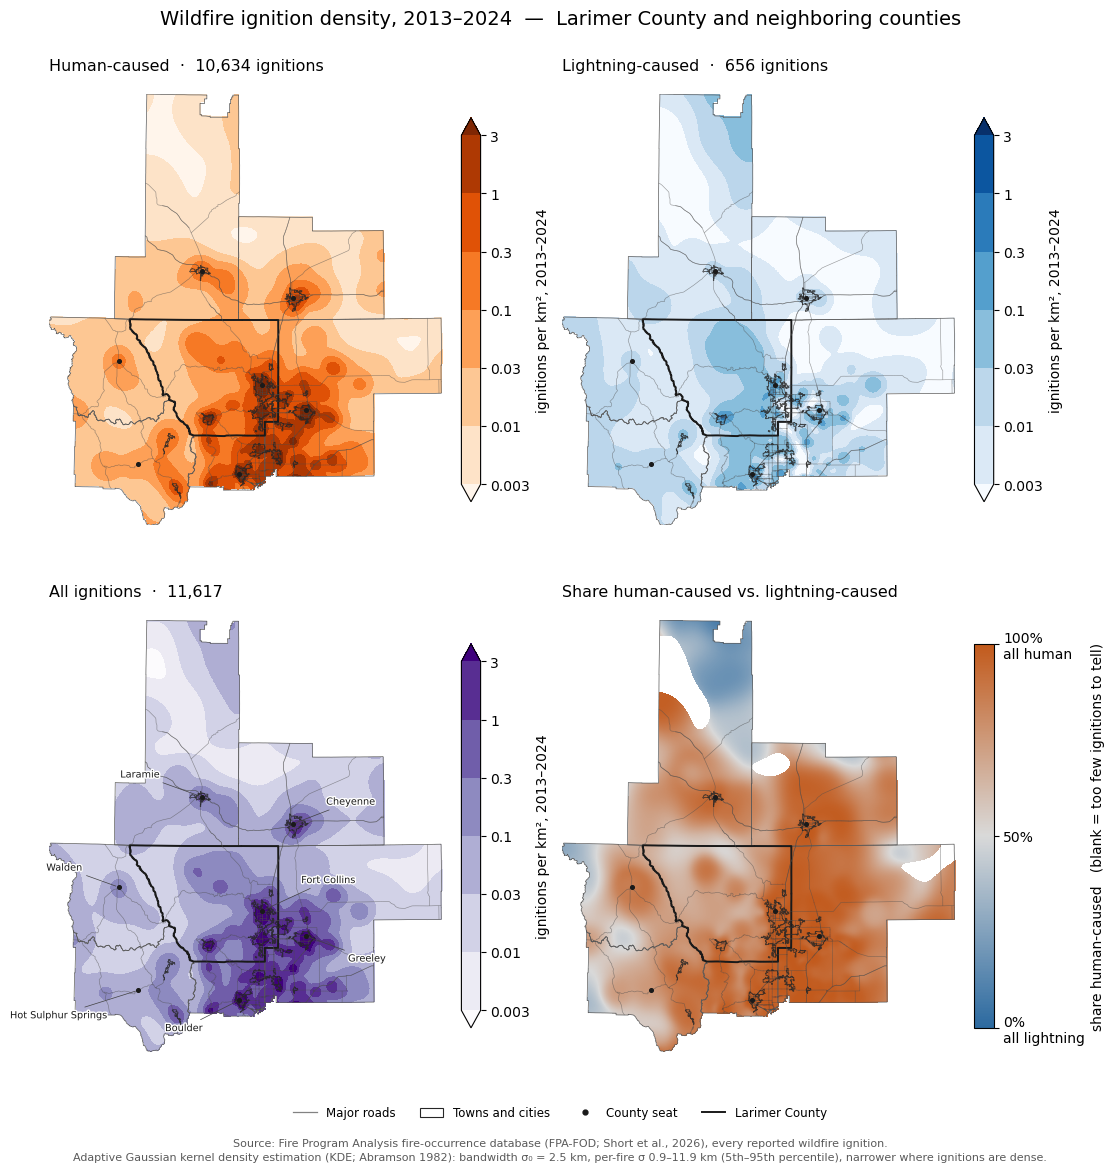

In [7]:
PLACE   = f"{FOCUS['NAME']} County and neighboring counties"
FIG_DIR = OUT / AOI_NAME / "figures"


def save(fig, name):
    FIG_DIR.mkdir(parents=True, exist_ok=True)
    fig.savefig(FIG_DIR / f"{name}.png", dpi=200, bbox_inches="tight", facecolor="white")


def _ramp(name):
    cm = plt.get_cmap(name).copy()
    cm.set_bad(alpha=0)
    return cm


RAMPS = {"human": _ramp("Oranges"), "natural": _ramp("Blues"), "all": _ramp("Purples"), "unknown": _ramp("Greys")}
DIV = LinearSegmentedColormap.from_list("nat_hum", ["#2c6aa0", "#d9d9d9", "#c25a1c"])
DIV.set_bad(alpha=0)
CAUSE_COLOR = {"human": "#c25a1c", "natural": "#2c6aa0", "unknown": "#8a8a8a"}
CAUSE_LABEL = {"human": "Human-caused", "natural": "Lightning-caused", "unknown": "Cause unknown"}
TITLES = {"human": "Human-caused", "natural": "Lightning-caused",
          "all": "All ignitions", "human_share": "Share human-caused vs. lightning-caused"}
AREA_WORDS = {"mi2": "square mile", "100mi2": "100 square miles", "km2": "km²", "100km2": "100 km²"}
HALO = [pe.withStroke(linewidth=2.5, foreground="white")]
# County-seat label offsets (points) — pushed off the dense Front Range corridor onto leader lines.
SEAT_OFFSETS = {"Fort Collins": (28, 22), "Greeley": (30, -16), "Boulder": (-26, -20), "Cheyenne": (24, 16),
                "Laramie": (-30, 16), "Walden": (-26, 14), "Hot Sulphur Springs": (-22, -18)}


def unit_label(ds):
    a = ds.attrs
    area = AREA_WORDS[a.get("density_area", "100km2")]
    if a.get("density_per_year", "True") == "True":
        return f"ignitions per year per {area}"
    return f"ignitions per {area}, {a['years'].replace('-', '–')}"


def footnote(ds):
    a = ds.attrs
    if a.get("adaptive") == "True":
        kde = (f"Adaptive Gaussian kernel density estimation (KDE; Abramson 1982): bandwidth σ₀ = "
               f"{a['bandwidth_m'] / 1000:g} km, per-fire σ {a['bandwidth_p05_m'] / 1000:.1f}–"
               f"{a['bandwidth_p95_m'] / 1000:.1f} km (5th–95th percentile), narrower where ignitions are dense.")
    else:
        kde = f"Gaussian kernel density estimation (KDE), bandwidth σ = {a['bandwidth_m'] / 1000:g} km."
    return ("Source: Fire Program Analysis fire-occurrence database (FPA-FOD; Short et al., 2026), "
            "every reported wildfire ignition.\n" + kde)


def _extent(ds):
    t, (ny, nx) = ds.rio.transform(), ds["all"].shape
    return (t.c, t.c + nx * t.a, t.f + ny * t.e, t.f)


def _outline(ax, aoi, focus):
    aoi.boundary.plot(ax=ax, color="0.35", lw=0.5)
    focus.boundary.plot(ax=ax, color="0.1", lw=1.4)
    ax.set_axis_off()


def add_reference(ax, labels=True):
    # Light reference layers: major roads, urban-area outlines, county seats.
    xlim, ylim = ax.get_xlim(), ax.get_ylim()
    roads.plot(ax=ax, color="0.3", lw=0.45, alpha=0.55, zorder=3)
    urban.boundary.plot(ax=ax, color="0.15", lw=0.6, alpha=0.8, zorder=3)
    ax.scatter(seats.geometry.x, seats.geometry.y, s=7, c="0.1", zorder=4)
    if labels:
        # Labels pulled off the dense corridor onto leader lines (offsets in points; SEAT_OFFSETS).
        for _, r in seats.iterrows():
            dx, dy = SEAT_OFFSETS.get(r["name"], (3, 3))
            lead = abs(dx) > 5 or abs(dy) > 5
            ax.annotate(r["name"], (r.geometry.x, r.geometry.y), xytext=(dx, dy), textcoords="offset points",
                        ha="left" if dx >= 0 else "right", va="center", fontsize=7, color="0.1",
                        path_effects=[pe.withStroke(linewidth=2, foreground="white")], zorder=4,
                        arrowprops=dict(arrowstyle="-", lw=0.5, color="0.25", shrinkA=1, shrinkB=2) if lead else None)
    ax.set_xlim(xlim)
    ax.set_ylim(ylim)


def reference_handles(focus_name=FOCUS["NAME"]):
    return [Line2D([], [], color="0.3", lw=0.9, alpha=0.7, label="Major roads"),
            Patch(facecolor="none", edgecolor="0.15", lw=0.8, label="Towns and cities"),
            Line2D([], [], ls="", marker="o", ms=3.5, color="0.1", label="County seat"),
            Line2D([], [], color="0.1", lw=1.4, label=f"{focus_name} County")]


def rate_norm(ds):
    # Classed log scale shared by every density panel: edges on the 1-3-10 sequence, each class ~3× the one below,
    # so equal colour steps mean equal ratios and a 10× gap between maps reads as two classes. Fixed edges
    # (CLASS_EDGES) keep figures comparable across runs; other units or extents fall back to the data's range.
    if CLASS_EDGES is not None and ds.attrs.get("density_area") == MAP_UNITS["area"] \
            and ds.attrs.get("density_per_year") == str(MAP_UNITS["per_year"]):
        return BoundaryNorm(CLASS_EDGES, ncolors=256, extend="both")
    a = ds["all"].values
    lo, hi = np.nanpercentile(a, 1), np.nanpercentile(a, 99.8)
    edges = [m * 10.0 ** e for e in range(-8, 8) for m in (1, 3) if lo <= m * 10.0 ** e <= hi]
    return BoundaryNorm(edges, ncolors=256, extend="both")


def show(ax, ds, var, norm=None):
    if var == "human_share":
        return ax.imshow(ds[var], extent=_extent(ds), cmap=DIV, norm=Normalize(0, 1), interpolation="nearest")
    return ax.imshow(ds[var], extent=_extent(ds), cmap=RAMPS[var], norm=norm or rate_norm(ds),
                     interpolation="nearest")


def density_colorbar(fig, im, ax, ds, **kw):
    cb = fig.colorbar(im, ax=ax, label=unit_label(ds), **kw)
    if isinstance(im.norm, BoundaryNorm):
        cb.set_ticks(im.norm.boundaries)
    cb.ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:g}"))   # 0.1, 1, 10 — not 10⁻¹
    cb.ax.yaxis.set_minor_formatter(FuncFormatter(lambda v, _: ""))
    return cb


def share_colorbar(fig, im, ax, **kw):
    cb = fig.colorbar(im, ax=ax, label="share human-caused   (blank = too few ignitions to tell)", **kw)
    cb.set_ticks([0, 0.5, 1])
    cb.set_ticklabels(["0%\nall lightning", "50%", "100%\nall human"])
    return cb


def kernel_label(ds):
    a = ds.attrs
    if a.get("adaptive") == "True":
        return (f"adaptive σ₀ = {a['bandwidth_m'] / 1000:g} km (fires: {a['bandwidth_p05_m'] / 1000:.1f}–"
                f"{a['bandwidth_p95_m'] / 1000:.1f} km, p5–p95)")
    return f"σ = {a['bandwidth_m'] / 1000:g} km"


def plot_idg(ds, aoi, focus, place, counts=None, norm=None, reference=True):
    norm = norm or rate_norm(ds)
    fig, axs = plt.subplots(2, 2, figsize=(11, 10.5), constrained_layout=True)
    for ax, var in zip(axs.flat, ["human", "natural", "all", "human_share"]):
        im = show(ax, ds, var, norm)
        _outline(ax, aoi, focus)
        if reference:
            add_reference(ax, labels=(var == "all"))      # town names on one panel only
        n = (counts or {}).get(var)
        ax.set_title(TITLES[var] + (f"  ·  {n:,}" + ("" if var == "all" else " ignitions") if n else ""),
                     loc="left", fontsize=11.5)
        if var == "human_share":
            share_colorbar(fig, im, ax, shrink=0.75)
        else:
            density_colorbar(fig, im, ax, ds, shrink=0.75)
    fig.suptitle(f"Wildfire ignition density, {ds.attrs['years'].replace('-', '–')}  —  {place}",
                 fontsize=14, y=1.035)
    if reference:
        fig.legend(handles=reference_handles(focus.NAME.iloc[0] if "NAME" in focus and len(focus) else ""),
                   loc="upper center", bbox_to_anchor=(0.5, 0.0), ncol=4, fontsize=8.5, frameon=False)
    fig.text(0.5, -0.04, footnote(ds), ha="center", va="top", fontsize=8, color="0.35", linespacing=1.5)
    return fig


COUNTS = {"human": int((inside.cause == "human").sum()), "natural": int((inside.cause == "natural").sum()),
          "all": len(inside)}
save(plot_idg(MAIN, aoi, focus, PLACE, counts=COUNTS), f"{AOI_NAME}_ignition_density")

## 5. Ignitions per year

The maps pool `YEARS`; this puts the time back. First, ignitions inside each county over the mapped years (the
same records as the maps), stacked by cause, on one shared scale so counties compare directly.

**Why the maps start where they do.** In these counties the 1992–2009 records are almost all reported by federal
agencies (Forest Service, Interior), so they cover federal land, mostly in the mountains. State & local reports
(Colorado's state forestry system `ST-NASF`, then InFORM from 2021) add the private-land and plains fires, which
are mostly human-caused. They begin in 2010, but 2011 is ~1,400 records with no cause and 2012 holds only
~30 — full state & local coverage starts in **2013** (table in §2). The second chart is the **federal agencies'
reports only**, which cover the whole 1992–2024 record (their own systems to 2019, IRWIN/InFORM after).

Ignitions per year, mean by county:
cause    human  natural  unknown  total
NAME                                   
Larimer  245.9     18.7      4.9  269.5
Weld     371.1     10.0      1.6  382.7
Boulder  192.8      6.8      3.5  203.1
Laramie   27.2      2.2     10.2   39.6
Albany    18.5      8.8      5.2   32.5
Grand     22.2      5.8      1.2   29.2
Jackson    8.5      2.6      0.7   11.8


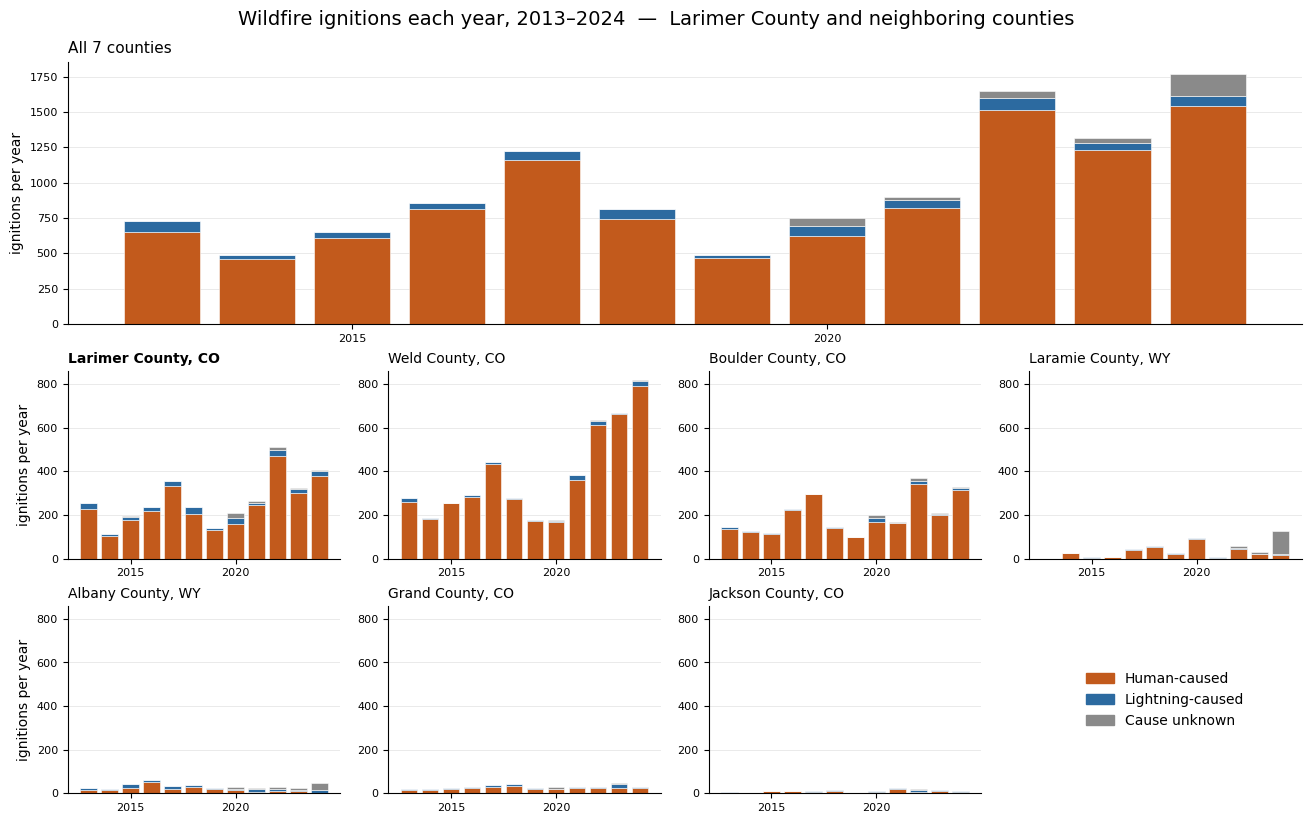

In [8]:
STATE_ABBR = {"08": "CO", "56": "WY", "31": "NE", "49": "UT", "20": "KS"}
CAUSES = ["human", "natural", "unknown"]
yrs = np.arange(YEARS[0], YEARS[1] + 1)
yearly = (inside.groupby(["NAME", "FIRE_YEAR", "cause"]).size()
          .unstack("cause", fill_value=0).reindex(columns=CAUSES, fill_value=0))
state_of = dict(zip(aoi.NAME, aoi.STATEFP.map(STATE_ABBR)))
order = [FOCUS["NAME"]] + [n for n in yearly.groupby(level="NAME").sum().sum(axis=1)
                           .sort_values(ascending=False).index if n != FOCUS["NAME"]]


def stacked_bars(ax, df, years=None):
    df = df.reindex(yrs if years is None else years, fill_value=0)
    bottom = np.zeros(len(df))
    for c in CAUSES:
        ax.bar(df.index, df[c], bottom=bottom, width=0.8, color=CAUSE_COLOR[c], edgecolor="white", linewidth=0.4)
        bottom += df[c].to_numpy()
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", color="0.9", lw=0.6)
    ax.set_axisbelow(True)
    ax.tick_params(labelsize=8)
    ax.xaxis.set_major_locator(MaxNLocator(nbins=5, steps=[1, 2, 5, 10], integer=True))


ncol = 4
nrow = int(np.ceil((len(order) + 1) / ncol))
fig = plt.figure(figsize=(13, 3.2 + 2.3 * nrow), constrained_layout=True)
gs = fig.add_gridspec(1 + nrow, ncol, height_ratios=[1.4] + [1] * nrow)
ax0 = fig.add_subplot(gs[0, :])
stacked_bars(ax0, yearly.groupby(level="FIRE_YEAR").sum())
ax0.set_title(f"All {len(order)} counties", loc="left", fontsize=11)
ax0.set_ylabel("ignitions per year")
axs = []
for i, name in enumerate(order):
    ax = fig.add_subplot(gs[1 + i // ncol, i % ncol], sharey=axs[0] if axs else None)
    stacked_bars(ax, yearly.loc[name])
    ax.set_title(f"{name} County, {state_of.get(name, '')}", loc="left", fontsize=10,
                 fontweight="bold" if name == FOCUS["NAME"] else "normal")
    if i % ncol == 0:
        ax.set_ylabel("ignitions per year")
    axs.append(ax)
leg = fig.add_subplot(gs[1 + len(order) // ncol, len(order) % ncol])
leg.axis("off")
leg.legend(handles=[Patch(color=CAUSE_COLOR[c], label=CAUSE_LABEL[c]) for c in CAUSES],
           loc="center", frameon=False, fontsize=10)
fig.suptitle(f"Wildfire ignitions each year, {YEARS[0]}–{YEARS[1]}  —  {PLACE}", fontsize=14, y=1.035)
save(fig, f"{AOI_NAME}_fires_per_year")
print("Ignitions per year, mean by county:")
print((yearly.groupby(level="NAME").sum() / len(yrs)).round(1).loc[order].assign(
    total=lambda d: d.sum(axis=1)).to_string())

2,607 federal-agency records; per year by cause, mean: {'human': 38.7, 'natural': 38.5, 'unknown': 1.8}


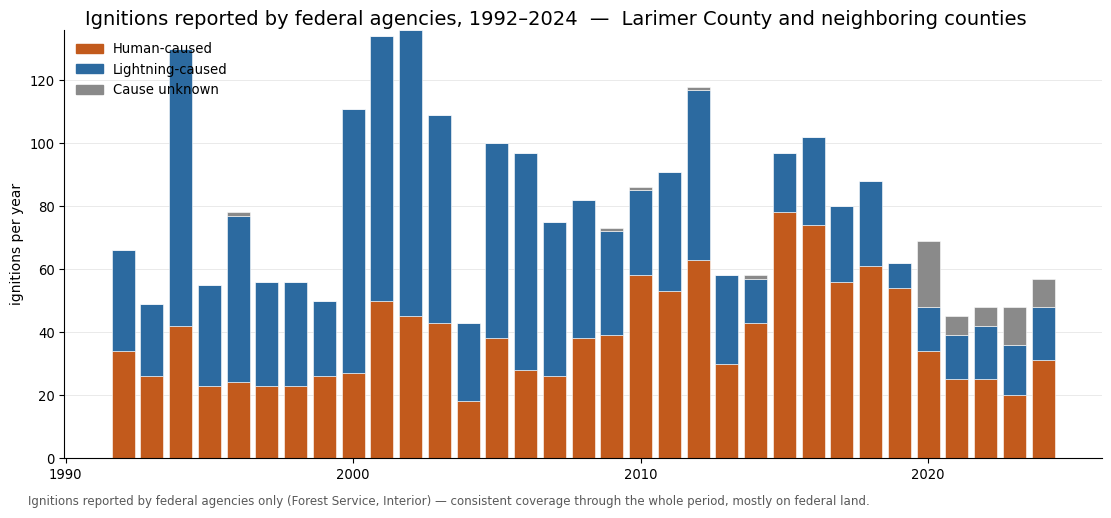

In [9]:
fed = inside_full[inside_full.reporter == "federal"]
rec_yrs = np.arange(RECORD_YEARS[0], RECORD_YEARS[1] + 1)
fed_yearly = (fed.groupby(["FIRE_YEAR", "cause"]).size().unstack("cause", fill_value=0)
              .reindex(index=rec_yrs, columns=CAUSES, fill_value=0))

fig, ax = plt.subplots(figsize=(11, 4.6), constrained_layout=True)
stacked_bars(ax, fed_yearly, years=rec_yrs)
ax.tick_params(labelsize=9.5)
ax.set_ylabel("ignitions per year")
ax.legend(handles=[Patch(color=CAUSE_COLOR[c], label=CAUSE_LABEL[c]) for c in CAUSES],
          loc="upper left", frameon=False, fontsize=9.5)
fig.suptitle(f"Ignitions reported by federal agencies, {RECORD_YEARS[0]}–{RECORD_YEARS[1]}  —  {PLACE}",
             fontsize=14, y=1.035)
fig.text(0.02, -0.02, "Ignitions reported by federal agencies only (Forest Service, Interior) — consistent coverage "
         "through the whole period, mostly on federal land.", fontsize=8.5, color="0.35", va="top")
save(fig, f"{AOI_NAME}_federal_record")
print(f"{len(fed):,} federal-agency records; per year by cause, mean:", (fed_yearly.mean()).round(1).to_dict())

## 6. Ignitions by cause

FPA-FOD's most detailed cause field in this release is `NWCG_GENERAL_CAUSE` (13 NWCG categories); the
agency-specific cause codes are not carried. FOD classes a fire *human* whenever lightning is ruled out, so most of
the "no specific cause" bar is human-classed fire whose cause was never found. Same records as the maps (`YEARS`, inside the AOI counties).

**"Other causes" is a reporting artefact, not a cause.** Of its ~3,660 records, ~3,650 come from InFORM in
2021–2024, the years "Undetermined" falls from 300–900 a year to 40–200 — state & local fires with no specific
cause were coded "Other" after the switch. The chart merges the two into one bar: about 69% of ignitions (72% of
human-caused) have no specific cause.

,ignitions,percent
NWCG_GENERAL_CAUSE,,
No specific cause recorded,8007,68.9
Recreation and ceremony,791,6.8
Lightning,656,5.6
Equipment and vehicle use,604,5.2
Debris and open burning,599,5.2
Smoking,382,3.3
Fireworks,171,1.5
Arson,144,1.2
Power lines and utilities,100,0.9


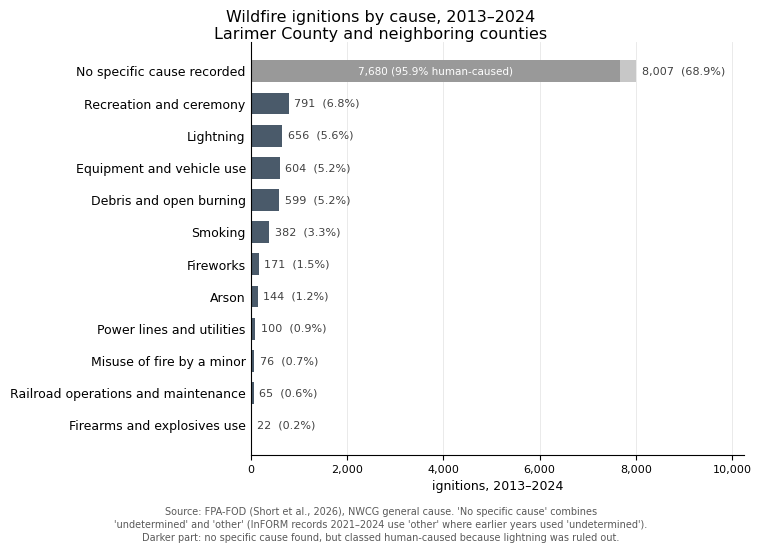

In [10]:
NO_CAUSE = "No specific cause recorded"
CAUSE_NAMES = {   # NWCG general cause → plain label; 'Other' and 'Undetermined' merged (see above)
    "Missing data/not specified/undetermined": NO_CAUSE,
    "Other causes": NO_CAUSE,
    "Power generation/transmission/distribution": "Power lines and utilities",
    "Arson/incendiarism": "Arson",
    "Natural": "Lightning",
}
general = inside.NWCG_GENERAL_CAUSE.fillna("Missing data/not specified/undetermined").replace(CAUSE_NAMES)
counts = general.value_counts().sort_values()                         # largest at the top
pct = counts / counts.sum() * 100

fig, ax = plt.subplots(figsize=(7.5, 4.6), constrained_layout=True)
colors = ["0.78" if n == NO_CAUSE else "#4a5a6a" for n in counts.index]
ax.barh(counts.index, counts, height=0.68, color=colors)
# Split the no-cause bar: the part FOD still classes as human-caused (lightning ruled out).
no_cause = general == NO_CAUSE
n_no, n_no_hum = int(no_cause.sum()), int((inside.cause[no_cause] == "human").sum())
y_no = list(counts.index).index(NO_CAUSE)
ax.barh(y_no, n_no_hum, height=0.68, color="0.6")
ax.annotate(f"{n_no_hum:,} ({n_no_hum / n_no * 100:.1f}% human-caused)", (n_no_hum / 2, y_no),
            ha="center", va="center", fontsize=7.5, color="white")
for y, (n, p) in enumerate(zip(counts, pct)):
    ax.annotate(f"{n:,}  ({p:.1f}%)", (n, y), xytext=(4, 0), textcoords="offset points", va="center",
                fontsize=8, color="0.25")
ax.set_xlim(0, counts.max() * 1.28)
ax.set_xlabel(f"ignitions, {YEARS[0]}–{YEARS[1]}", fontsize=9)
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="x", color="0.9", lw=0.6)
ax.set_axisbelow(True)
ax.tick_params(axis="y", length=0, labelsize=9)
ax.tick_params(axis="x", labelsize=8)
ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:,.0f}"))
fig.suptitle(f"Wildfire ignitions by cause, {YEARS[0]}–{YEARS[1]}\n{PLACE}", fontsize=11.5, y=1.06)
fig.text(0.5, -0.02, "Source: FPA-FOD (Short et al., 2026), NWCG general cause. 'No specific cause' combines\n"
         "'undetermined' and 'other' (InFORM records 2021–2024 use 'other' where earlier years used 'undetermined').\n"
         "Darker part: no specific cause found, but classed human-caused because lightning was ruled out.",
         ha="center", va="top", fontsize=7, color="0.35", linespacing=1.4)
save(fig, f"{AOI_NAME}_ignitions_by_cause")
pd.DataFrame({"ignitions": counts, "percent": pct.round(1)}).iloc[::-1]

## 7. Large fires by cause

FOD fires of at least `LARGE_AC` acres inside the AOI, drawn where each was discovered — shape and colour by cause,
area ∝ fire size. Written to `OUT/<aoi>/large_fires_ge<LARGE_AC>ac.gpkg`.

In [11]:
large = (inside[inside.FIRE_SIZE >= LARGE_AC]
         .sort_values("FIRE_SIZE", ascending=False).reset_index(drop=True))
large[["FIRE_NAME", "FIRE_YEAR", "FIRE_SIZE", "cause", "NWCG_GENERAL_CAUSE", "NAME", "geometry"]].to_file(
    OUT / AOI_NAME / f"large_fires_ge{LARGE_AC}ac.gpkg", layer="fires")
print(f"{len(large)} fires ≥ {LARGE_AC:,} ac:", large.cause.value_counts().to_dict())
large[["FIRE_NAME", "FIRE_YEAR", "FIRE_SIZE", "cause", "NWCG_GENERAL_CAUSE", "NAME"]].head(15)

32 fires ≥ 1,000 ac: {'human': 16, 'natural': 8, 'unknown': 8}


,FIRE_NAME,FIRE_YEAR,FIRE_SIZE,cause,NWCG_GENERAL_CAUSE,NAME
0,CAMERON PEAK,2020,208913.00,human,Missing data/not specified/undetermined,Larimer
1,EAST TROUBLESOME,2020,193812.00,human,Recreation and ceremony,Grand
2,BEAVER CREEK,2016,38380.00,human,Recreation and ceremony,Jackson
3,BRITANIA MOUNTAIN FIRE,2018,32089.00,natural,Natural,Albany
4,RYAN,2018,28584.00,human,Recreation and ceremony,Jackson
5,BADGER CREEK,2018,21357.00,human,Equipment and vehicle use,Albany
6,WILLIAMS FORK,2020,14833.00,human,Missing data/not specified/undetermined,Grand
7,UNKNOWN,2015,12699.00,human,Missing data/not specified/undetermined,Weld
8,CALWOOD,2020,10106.00,unknown,Missing data/not specified/undetermined,Boulder
9,ALEXANDER MOUNTAIN,2024,9668.00,human,Arson/incendiarism,Larimer


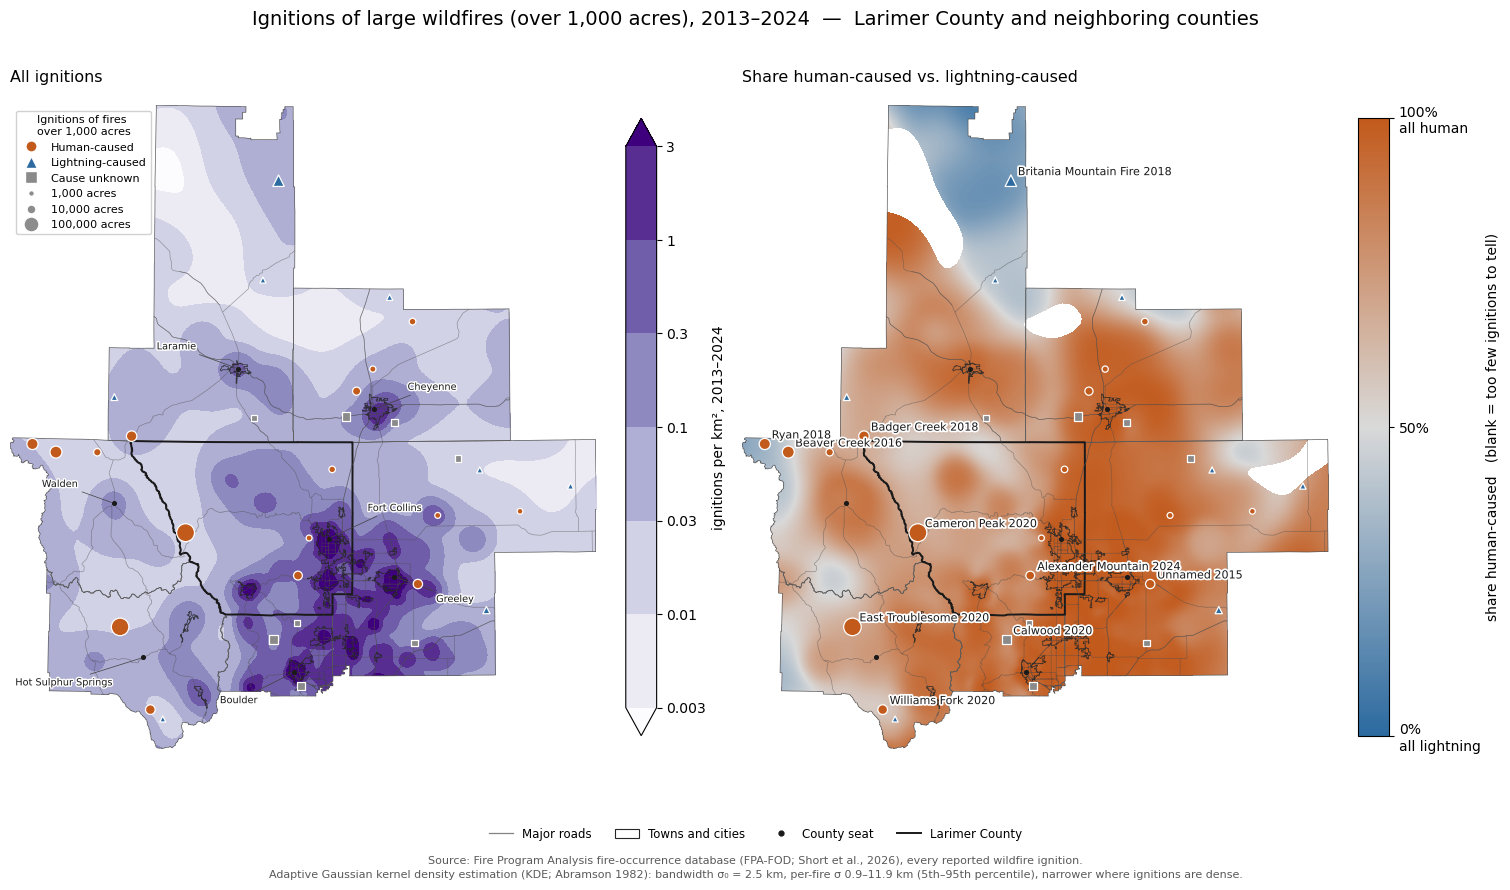

In [12]:
CAUSE_STYLE = {   # colour + shape, so cause never rides on colour alone
    c: dict(color=CAUSE_COLOR[c], marker=m, label=CAUSE_LABEL[c])
    for c, m in [("human", "o"), ("natural", "^"), ("unknown", "s")]
}
_size = lambda ac: 6 + 0.35 * np.sqrt(ac)


def add_large_fires(ax, large, n_labels=0, legend=True):
    for cause, st in CAUSE_STYLE.items():
        sub = large[large.cause == cause]
        ax.scatter(sub.geometry.x, sub.geometry.y, s=_size(sub.FIRE_SIZE), c=st["color"], marker=st["marker"],
                   edgecolors="white", linewidths=0.9, zorder=5)
    for _, r in large.head(n_labels).iterrows():
        raw = str(r.FIRE_NAME or "").strip()
        name = "Unnamed" if raw.upper() in {"", "UNKNOWN", "NONE", "UNNAMED"} else raw.title()
        ax.annotate(f"{name} {r.FIRE_YEAR}", (r.geometry.x, r.geometry.y), xytext=(5, 4),
                    textcoords="offset points", fontsize=8, color="0.1", path_effects=HALO, zorder=6)
    if legend:
        handles = [Line2D([], [], ls="", marker=st["marker"], color=st["color"], markeredgecolor="white",
                          markersize=8, label=st["label"]) for st in CAUSE_STYLE.values()]
        handles += [Line2D([], [], ls="", marker="o", color="0.55", markeredgecolor="white",
                           markersize=np.sqrt(_size(ac)), label=f"{ac:,} acres") for ac in (1_000, 10_000, 100_000)]
        ax.legend(handles=handles, loc="upper left", fontsize=8, frameon=True, framealpha=0.9,
                  title=f"Ignitions of fires\nover {LARGE_AC:,} acres", title_fontsize=8)


fig, axs = plt.subplots(1, 2, figsize=(15, 7.8), constrained_layout=True)
for ax, var in [(axs[0], "all"), (axs[1], "human_share")]:
    im = show(ax, MAIN, var)
    _outline(ax, aoi, focus)
    add_reference(ax, labels=(var == "all"))
    add_large_fires(ax, large, n_labels=10 if var == "human_share" else 0, legend=(var == "all"))
    ax.set_title(TITLES[var], loc="left", fontsize=11.5)
    if var == "human_share":
        share_colorbar(fig, im, ax, shrink=0.8)
    else:
        density_colorbar(fig, im, ax, MAIN, shrink=0.8)
fig.suptitle(f"Ignitions of large wildfires (over {LARGE_AC:,} acres), {YEARS[0]}–{YEARS[1]}  —  {PLACE}",
             fontsize=14, y=1.035)
fig.legend(handles=reference_handles(), loc="upper center", bbox_to_anchor=(0.5, 0.0), ncol=4, fontsize=8.5,
           frameon=False)
fig.text(0.5, -0.05, footnote(MAIN), ha="center", va="top", fontsize=8, color="0.35", linespacing=1.5)
save(fig, f"{AOI_NAME}_large_fires")

## 8. Technical — difference map, fixed vs adaptive kernel

Not part of the public figure set.

**Difference** (human-caused − lightning-caused, same units as the maps) says the same thing as the share map in a harder-to-read
form; the GeoTIFF is written in §3.

**Fixed vs adaptive.** A fixed σ small enough for the Front Range corridor turns the sparse lightning record into
isolated dots and blanks most of the share map; one wide enough for the mountains washes out the corridor. The
adaptive kernel narrows where fires are dense and widens where they are sparse. The last map is the σ it used, per
cell. σ comes from all fires pooled, so a lightning fire in the Front Range corridor gets the corridor's narrow
kernel — that keeps the share comparing like with like, and is why the lightning layer stays spotty on the plains,
where lightning fires are a small minority among many human ones. Not written to disk.

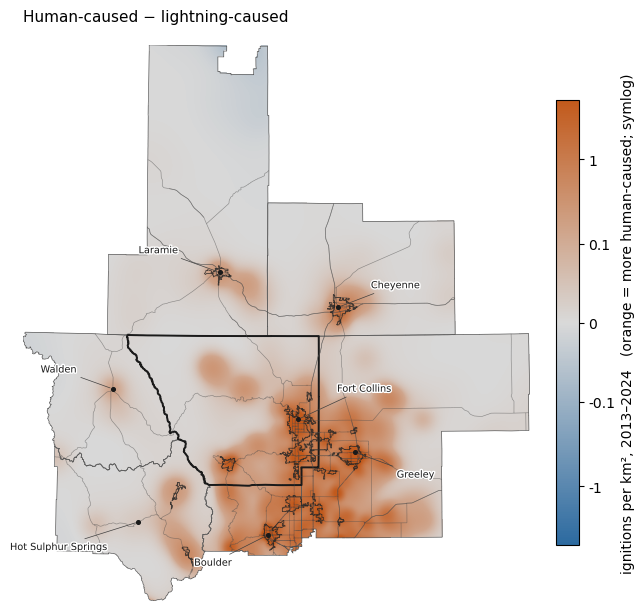

In [13]:
def plot_difference(ds, aoi, focus, linthresh=None):
    d = ds["difference"].values
    vmax = np.nanpercentile(np.abs(d), 99.5)
    linthresh = linthresh or vmax / 50
    fig, ax = plt.subplots(figsize=(6.5, 6), constrained_layout=True)
    im = ax.imshow(d, extent=_extent(ds), cmap=DIV, interpolation="nearest",
                   norm=SymLogNorm(linthresh=linthresh, vmin=-vmax, vmax=vmax, base=10))
    _outline(ax, aoi, focus)
    add_reference(ax)
    ax.set_title("Human-caused − lightning-caused", loc="left", fontsize=11)
    cb = fig.colorbar(im, ax=ax, shrink=0.8, label=f"{unit_label(ds)}   (orange = more human-caused; symlog)")
    cb.ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:g}"))
    return fig


plot_difference(MAIN, aoi, focus);

  [ignition_density_grid] 3392×3090 @ 90 m, σ=2,000 m, 12 yr; points used: human 22,187, natural 1,307, unknown 504, all 23,998
  [ignition_density_grid] 3392×3090 @ 90 m, adaptive σ₀=1,000 m (fires p5–p95 383–3,734 m), 12 yr; points used: human 21,389, natural 1,313, unknown 515, all 23,217
  [ignition_density_grid] 3392×3090 @ 90 m, adaptive σ₀=2,000 m (fires p5–p95 742–9,110 m), 12 yr; points used: human 22,328, natural 1,545, unknown 556, all 24,429
  [ignition_density_grid] 3392×3090 @ 90 m, adaptive σ₀=2,500 m (fires p5–p95 917–11,880 m), 12 yr; points used: human 22,813, natural 1,652, unknown 568, all 25,033


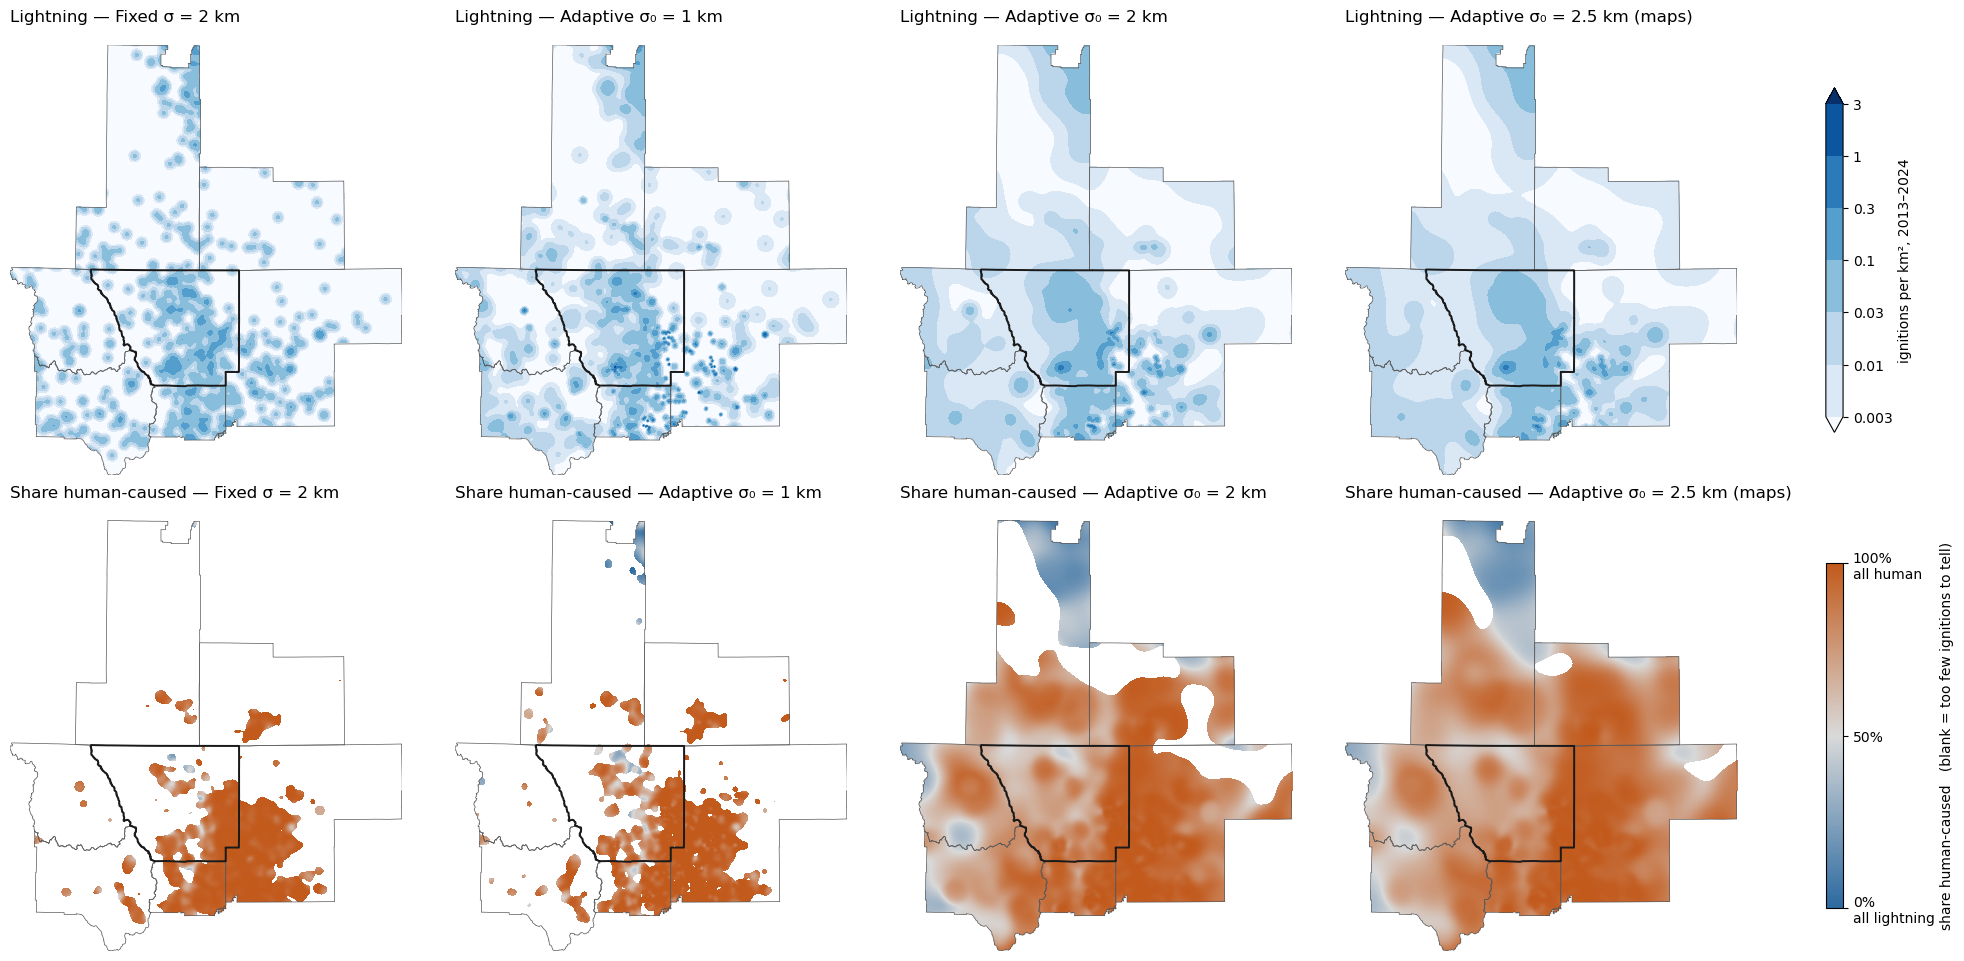

In [14]:
variants = {
    "Fixed σ = 2 km":     dict(bandwidth_m=2_000, adaptive=False),
    "Adaptive σ₀ = 1 km": dict(bandwidth_m=1_000, adaptive=True),
    "Adaptive σ₀ = 2 km": dict(bandwidth_m=2_000, adaptive=True),
    "Adaptive σ₀ = 2.5 km (maps)": dict(bandwidth_m=2_500, adaptive=True),
}
cmp = {k: convert_density_units(ignition_density_grid(fod, aoi, crs=CRS, res_m=RES_M, trim=TRIM, years=YEARS, **v),
                                **MAP_UNITS)
       for k, v in variants.items()}
norm = rate_norm(MAIN)
fig, axs = plt.subplots(2, len(cmp), figsize=(5 * len(cmp), 9.5), constrained_layout=True)
for j, (lab, ds) in enumerate(cmp.items()):
    im0 = show(axs[0, j], ds, "natural", norm)
    im1 = show(axs[1, j], ds, "human_share")
    axs[0, j].set_title(f"Lightning — {lab}", loc="left")
    axs[1, j].set_title(f"Share human-caused — {lab}", loc="left")
    for ax in axs[:, j]:
        _outline(ax, aoi, focus)
density_colorbar(fig, im0, axs[0, :], MAIN, shrink=0.8)
share_colorbar(fig, im1, axs[1, :], shrink=0.8);

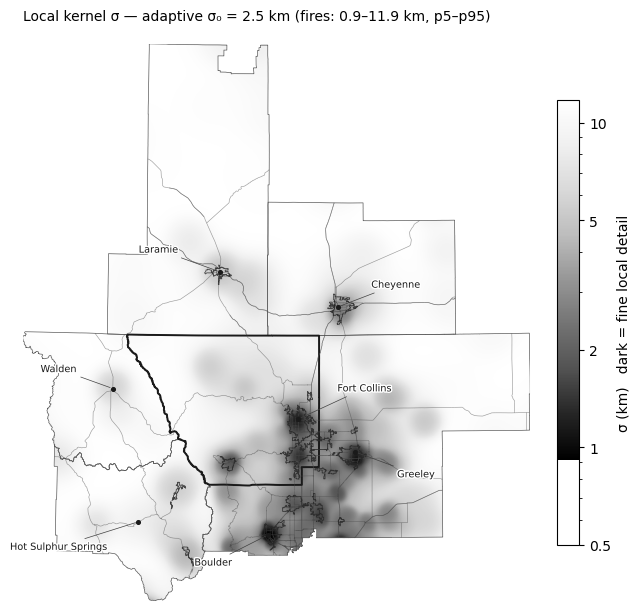

In [15]:
fig, ax = plt.subplots(figsize=(6.5, 6), constrained_layout=True)
bw_km = MAIN["bandwidth_local"] / 1000
im = ax.imshow(bw_km, extent=_extent(MAIN), cmap=_ramp("Greys_r"), interpolation="nearest",
               norm=LogNorm(vmin=float(bw_km.min()), vmax=float(bw_km.max())))
_outline(ax, aoi, focus)
add_reference(ax)
ax.set_title(f"Local kernel σ — {kernel_label(MAIN)}", loc="left", fontsize=10)
cb = fig.colorbar(im, ax=ax, shrink=0.8, label="σ (km)   dark = fine local detail")
cb.set_ticks([0.5, 1, 2, 5, 10]); cb.set_ticklabels(["0.5", "1", "2", "5", "10"]);

## 9. Larger extents — pyrome, westwide, CONUS

Same calls with a different AOI. A Colorado pyrome stays in UTM 13N at 90 m; westwide and CONUS switch to CONUS
Albers (EPSG:5070, cells nest LANDFIRE pixels) at 1 km — CONUS is ~4,600 × 2,900 cells (≈50 MB per layer), a few
seconds to smooth; at 90 m it would be ~1.6 G cells per layer. Cost is otherwise the FOD read (≈2.7 M records
CONUS-wide).

Pyromes on disk cover Colorado only (`CO_Pyromes.gpkg`); westwide/CONUS AOIs are built by dissolving TIGER counties.
Coastal and international edges are biased low (no FOD records beyond them to smooth in). Off by default.

In [16]:
RUN_PYROME = False     # one Colorado pyrome, UTM 13N, 90 m
RUN_WEST   = False     # 11 western states, Albers, 1 km
RUN_CONUS  = False     # lower 48, Albers, 1 km

WEST    = ["04", "06", "08", "16", "30", "32", "35", "41", "49", "53", "56"]
NOT_L48 = ["02", "15", "60", "66", "69", "72", "78"]
LARGE_EXTENT = {f"all_1km_adapt{BANDWIDTH_M / 1000:g}km": dict(sizes=None, res_m=1_000, bandwidth_m=BANDWIDTH_M, adaptive=True,
                                         crs="EPSG:5070")}

if RUN_PYROME:
    pyromes = gpd.read_file(PYROME_FP).to_crs(CRS)
    p_aoi = pyromes[pyromes.PYROME.astype(int) == 46]
    p_fod = load_fod(FOD_FP, aoi=p_aoi, buffer_m=READ_PAD_M, years=YEARS).to_crs(CRS)
    p_grids = run_products(p_fod, p_aoi, "pyrome46", PRODUCTS)
    plot_idg(next(iter(p_grids.values())), p_aoi, p_aoi, "Pyrome 46", reference=False)

for run, name, keep in [(RUN_WEST, "west", lambda c: c.STATEFP.isin(WEST)),
                        (RUN_CONUS, "conus", lambda c: ~c.STATEFP.isin(NOT_L48))]:
    if not run:
        continue
    big = counties[keep(counties)].to_crs(5070).dissolve()[["geometry"]]
    t0 = time.time()
    big_fod = load_fod(FOD_FP, aoi=big, buffer_m=READ_PAD_M, years=YEARS).to_crs(5070)
    print(f"read in {time.time() - t0:.0f} s")
    big_grids = run_products(big_fod, big, name, LARGE_EXTENT)
    plot_idg(next(iter(big_grids.values())), big, big.iloc[:0], name, reference=False)